# Fraud Detection — Version 1 (Classical Machine Learning)

**Goal:** predict whether a mobile-money transaction is fraudulent (`isFraud`) using classical ML models.

**Pipeline:**
1. Setup & data loading
2. Exploratory Data Analysis (EDA)
3. Data cleaning (incl. removing a leaky feature)
4. Feature engineering
5. Encoding
6. Train / test split
7. Class imbalance handling
8. Model training (Logistic Regression, Decision Tree, Random Forest, XGBoost)
9. Evaluation & comparison
10. Hyperparameter tuning + threshold tuning
11. Feature importance
12. Robustness check
13. Save model & prediction function

## 1. Setup & Data Loading

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)
from xgboost import XGBClassifier

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "e:\python\.venv\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "e:\python\.venv\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "e:\python\.venv\Lib\site-packages\ipykernel\kernelapp.py", line 758, in start
    self.io_loop.start()
  File "e:\python\.venv\Lib\site-packages\tornado\platform\asyncio.py", l

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "e:\python\.venv\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "e:\python\.venv\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "e:\python\.venv\Lib\site-packages\ipykernel\kernelapp.py", line 758, in start
    self.io_loop.start()
  File "e:\python\.venv\Lib\site-packages\tornado\platform\asyncio.py", l

AttributeError: _ARRAY_API not found

In [2]:
df = pd.read_csv('Fraud_Analysis_Dataset.csv')
print('Shape:', df.shape)
df.head()

Shape: (11142, 10)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.0,C1305486145,181.0,0.0,C553264065,0.0,0.0,1
1,1,CASH_OUT,181.0,C840083671,181.0,0.0,C38997010,21182.0,0.0,1
2,1,TRANSFER,2806.0,C1420196421,2806.0,0.0,C972765878,0.0,0.0,1
3,1,CASH_OUT,2806.0,C2101527076,2806.0,0.0,C1007251739,26202.0,0.0,1
4,1,TRANSFER,20128.0,C137533655,20128.0,0.0,C1848415041,0.0,0.0,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11142 entries, 0 to 11141
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            11142 non-null  int64  
 1   type            11142 non-null  object 
 2   amount          11142 non-null  float64
 3   nameOrig        11142 non-null  object 
 4   oldbalanceOrg   11142 non-null  float64
 5   newbalanceOrig  11142 non-null  float64
 6   nameDest        11142 non-null  object 
 7   oldbalanceDest  11142 non-null  float64
 8   newbalanceDest  11142 non-null  float64
 9   isFraud         11142 non-null  int64  
dtypes: float64(5), int64(2), object(3)
memory usage: 870.6+ KB


In [5]:
print('Missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
df.describe().T

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
step,11142.0,8.717645e+00,1.606748e+01,1.00,2.0000,6.000,7.0000,95.0
amount,11142.0,2.131915e+05,7.600650e+05,2.39,4946.6175,16761.260,154336.5750,10000000.0
oldbalanceOrg,11142.0,9.241173e+05,2.143004e+06,0.00,427.0000,28169.500,304085.4800,19900000.0
newbalanceOrig,11142.0,8.249576e+05,2.089894e+06,0.00,0.0000,4420.605,111412.6350,13000000.0
oldbalanceDest,11142.0,8.883541e+05,2.601376e+06,0.00,0.0000,0.000,271155.4725,33000000.0
newbalanceDest,11142.0,1.103211e+06,2.982447e+06,0.00,0.0000,0.000,318637.3600,34600000.0
isFraud,11142.0,1.024951e-01,3.033119e-01,0.00,0.0000,0.000,0.0000,1.0


## 2. Exploratory Data Analysis

### 2.1 Target distribution

isFraud
0    10000
1     1142
Name: count, dtype: int64
Fraud rate: 10.25%


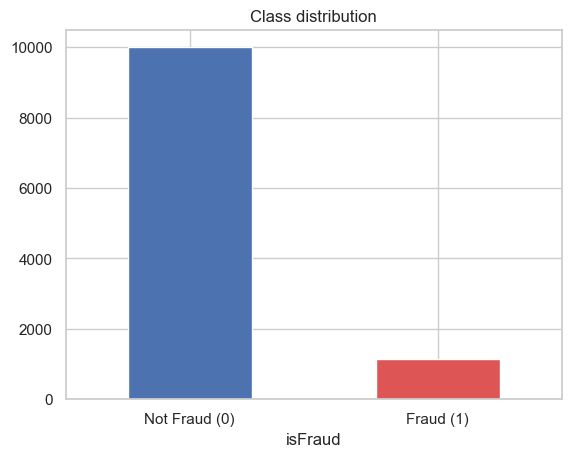

In [6]:
counts = df['isFraud'].value_counts()
print(counts)
print(f"Fraud rate: {df['isFraud'].mean():.2%}")

ax = counts.plot(kind='bar', color=['#4C72B0', '#DD5555'])
ax.set_xticklabels(['Not Fraud (0)', 'Fraud (1)'], rotation=0)
ax.set_title('Class distribution')
plt.show()

The dataset is **imbalanced** (~10% fraud), so accuracy alone is a misleading metric.

### 2.2 Fraud by transaction type

isFraud       0     1    All
type                        
CASH_IN    1951     0   1951
CASH_OUT   1293   578   1871
DEBIT       346     0    346
PAYMENT    5510     0   5510
TRANSFER    900   564   1464
All       10000  1142  11142


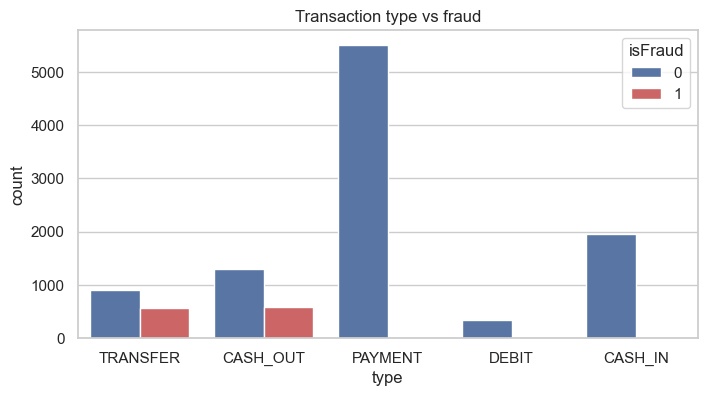

In [7]:
print(pd.crosstab(df['type'], df['isFraud'], margins=True))

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='type', hue='isFraud', palette=['#4C72B0', '#DD5555'])
plt.title('Transaction type vs fraud')
plt.show()

**Insight:** fraud occurs **only** in `TRANSFER` and `CASH_OUT`. This matches the description: fraudsters take over an account, transfer funds out, then cash out.

### 2.3 Transaction amount

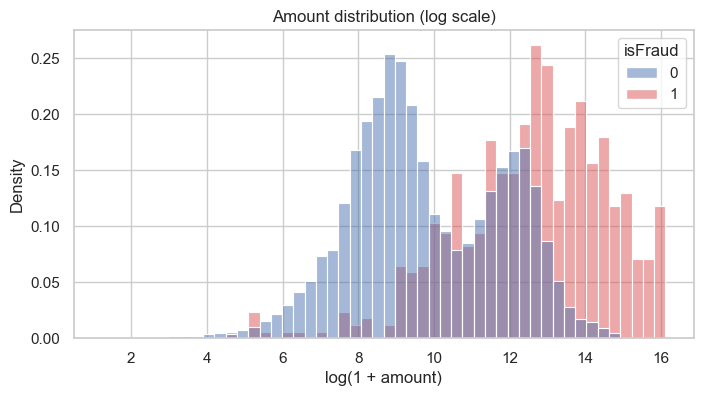

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,10000.0,1.013397e+05,2.260189e+05,2.39,4373.515,12725.235,1.139094e+05,3776389.09
1,1142.0,1.192629e+06,2.030599e+06,119.00,86070.170,353179.450,1.248759e+06,10000000.00


In [8]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x=np.log1p(df['amount']), hue='isFraud', bins=50,
             stat='density', common_norm=False, palette=['#4C72B0', '#DD5555'])
plt.xlabel('log(1 + amount)')
plt.title('Amount distribution (log scale)')
plt.show()

df.groupby('isFraud')['amount'].describe()

### 2.4 Does fraud empty the origin account?

In [9]:
emptied = (df['newbalanceOrig'] == 0)
full_amount = (df['amount'] - df['oldbalanceOrg']).abs() < 1
print('Origin balance emptied   -> fraud: {:.1%} | normal: {:.1%}'.format(
    emptied[df.isFraud == 1].mean(), emptied[df.isFraud == 0].mean()))
print('Amount == whole balance  -> fraud: {:.1%} | normal: {:.1%}'.format(
    full_amount[df.isFraud == 1].mean(), full_amount[df.isFraud == 0].mean()))

Origin balance emptied   -> fraud: 99.2% | normal: 40.3%
Amount == whole balance  -> fraud: 97.1% | normal: 0.0%


### 2.5 Merchant destinations

In [10]:
is_merchant = df['nameDest'].str.startswith('M')
print(pd.crosstab(is_merchant, df['isFraud'], rownames=['dest_is_merchant']))

isFraud              0     1
dest_is_merchant            
False             4490  1142
True              5510     0


No fraud goes to merchant (`M...`) accounts.

### 2.6 ⚠️ Data leakage check: `step`

           count       mean        std  min   25%   50%    75%   max
isFraud                                                             
0        10000.0   4.200500   2.484616  1.0   1.0   5.0   7.00   7.0
1         1142.0  48.272329  26.868203  1.0  25.0  48.0  70.75  95.0


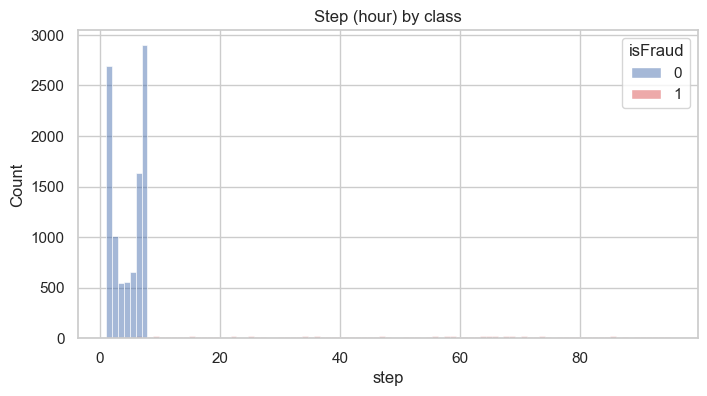

In [11]:
print(df.groupby('isFraud')['step'].describe())

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='step', hue='isFraud', bins=95, palette=['#4C72B0', '#DD5555'])
plt.title('Step (hour) by class')
plt.show()

**All non-fraud rows have `step` between 1 and 7, while fraud spans 1–95.** This is an artefact of how this sample was drawn, not real behaviour.
A model would simply learn *"step > 7 → fraud"* and fail on real data, so **`step` is dropped**.

### 2.7 Correlation heatmap

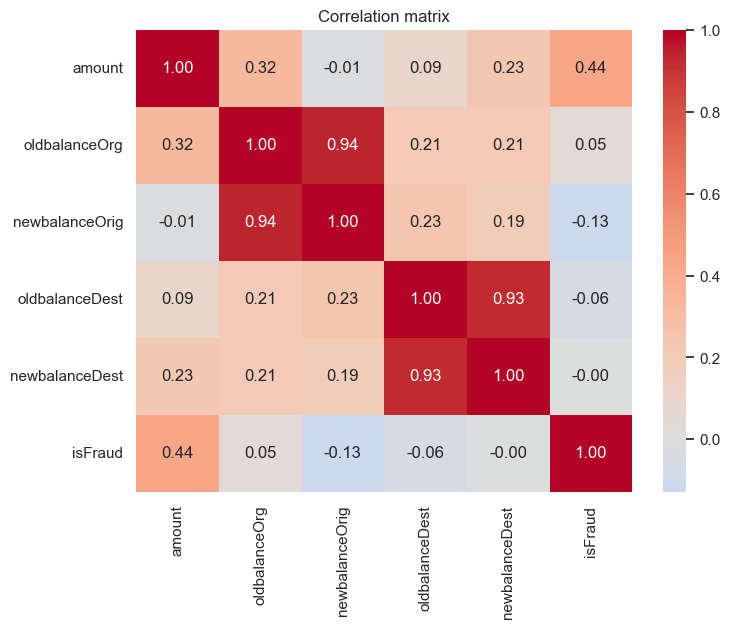

In [12]:
num_cols = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud']
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.show()

## 3–5. Data Cleaning, Feature Engineering & Encoding

One reusable function so the **same transformations** are applied at training and prediction time.

| Feature | Meaning |
|---|---|
| `errorBalanceOrig` | `oldbalanceOrg - amount - newbalanceOrig` (should be 0 for a consistent transaction) |
| `errorBalanceDest` | `oldbalanceDest + amount - newbalanceDest` |
| `orig_emptied` | origin account balance is 0 after transaction |
| `amount_to_balance` | fraction of the origin balance that was moved |
| `log_amount` | log-transformed amount (reduces skew) |
| `dest_is_merchant` | recipient starts with `M` |
| `type_*` | one-hot encoded transaction type |

Dropped: `step` (leakage), `nameOrig` (unique ID), `nameDest` (ID, replaced by `dest_is_merchant`).

In [13]:
TYPES = ['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']

def build_features(data: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=data.index)
    X['amount'] = data['amount']
    X['oldbalanceOrg'] = data['oldbalanceOrg']
    X['newbalanceOrig'] = data['newbalanceOrig']
    X['oldbalanceDest'] = data['oldbalanceDest']
    X['newbalanceDest'] = data['newbalanceDest']

    # engineered features
    X['errorBalanceOrig'] = data['oldbalanceOrg'] - data['amount'] - data['newbalanceOrig']
    X['errorBalanceDest'] = data['oldbalanceDest'] + data['amount'] - data['newbalanceDest']
    X['orig_emptied'] = (data['newbalanceOrig'] == 0).astype(int)
    X['amount_to_balance'] = data['amount'] / (data['oldbalanceOrg'] + 1)
    X['log_amount'] = np.log1p(data['amount'])
    X['dest_is_merchant'] = data['nameDest'].str.startswith('M').astype(int)

    # one-hot encode type with a fixed set of columns
    for t in TYPES:
        X[f'type_{t}'] = (data['type'] == t).astype(int)
    return X

X = build_features(df)
y = df['isFraud']
FEATURES = list(X.columns)
print(X.shape)
X.head()

(11142, 16)


,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,errorBalanceOrig,errorBalanceDest,orig_emptied,amount_to_balance,log_amount,dest_is_merchant,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,181.0,181.0,0.0,0.0,0.0,0.0,181.0,1,0.994505,5.204007,0,0,0,0,0,1
1,181.0,181.0,0.0,21182.0,0.0,0.0,21363.0,1,0.994505,5.204007,0,0,1,0,0,0
2,2806.0,2806.0,0.0,0.0,0.0,0.0,2806.0,1,0.999644,7.939872,0,0,0,0,0,1
3,2806.0,2806.0,0.0,26202.0,0.0,0.0,29008.0,1,0.999644,7.939872,0,0,1,0,0,0
4,20128.0,20128.0,0.0,0.0,0.0,0.0,20128.0,1,0.999950,9.909917,0,0,0,0,0,1


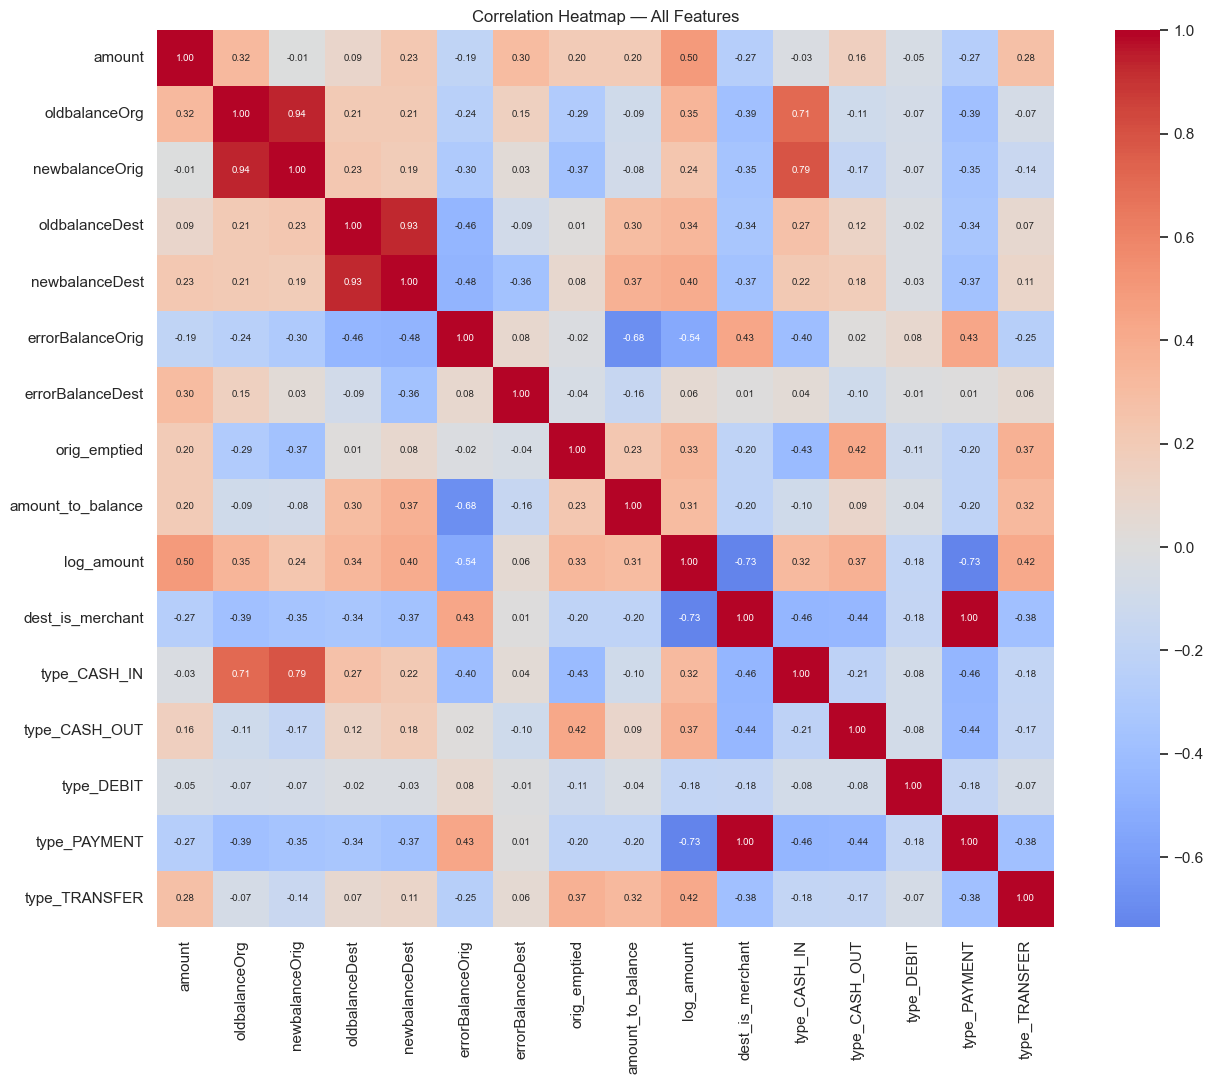

In [14]:
plt.figure(figsize=(14, 11))
sns.heatmap(X.corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f',
            square=True, annot_kws={'size': 7})
plt.title('Correlation Heatmap — All Features')
plt.tight_layout()
plt.show()

## 6. Train / Test Split (stratified)

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, f'fraud rate {y_train.mean():.2%}')
print('Test :', X_test.shape,  f'fraud rate {y_test.mean():.2%}')

Train: (8913, 16) fraud rate 10.25%
Test : (2229, 16) fraud rate 10.23%


## 7. Handling Class Imbalance

We use **class weighting** (`class_weight='balanced'` / XGBoost `scale_pos_weight`) so the models penalise missed fraud more.
This avoids generating synthetic rows. (SMOTE from `imblearn` is an alternative — apply it only on the training set.)

In [14]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight = {scale_pos_weight:.2f}')

scale_pos_weight = 8.75


## 8. Model Training

In [16]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE))
    ]),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', max_depth=6, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                            n_jobs=-1, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=5,
                             scale_pos_weight=scale_pos_weight, eval_metric='logloss',
                             random_state=RANDOM_STATE, n_jobs=-1),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f'Trained: {name}')

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: XGBoost


## 9. Evaluation & Comparison

For fraud detection, **Recall** (catching fraud) and **PR-AUC** matter most; accuracy is shown only for reference.

In [17]:
def evaluate(model, X_, y_, threshold=0.5):
    proba = model.predict_proba(X_)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        'Accuracy': accuracy_score(y_, pred),
        'Precision': precision_score(y_, pred),
        'Recall': recall_score(y_, pred),
        'F1': f1_score(y_, pred),
        'ROC-AUC': roc_auc_score(y_, proba),
        'PR-AUC': average_precision_score(y_, proba),
    }

results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in models.items()}).T
results.sort_values('F1', ascending=False).style.format('{:.4f}').background_gradient(cmap='Greens')

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
XGBoost,0.9978,0.9956,0.9825,0.9890,0.9968,0.9930
Random Forest,0.9978,1.0000,0.9781,0.9889,0.9949,0.9901
Decision Tree,0.9960,0.9824,0.9781,0.9802,0.9929,0.9863
Logistic Regression,0.9587,0.7208,0.9737,0.8284,0.9957,0.9788


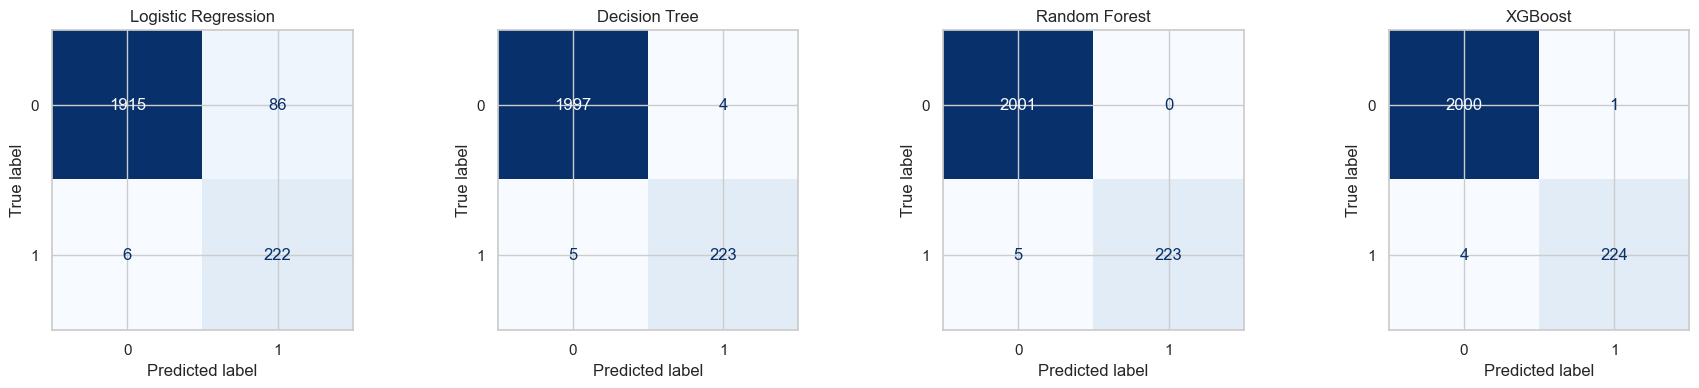

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout()
plt.show()

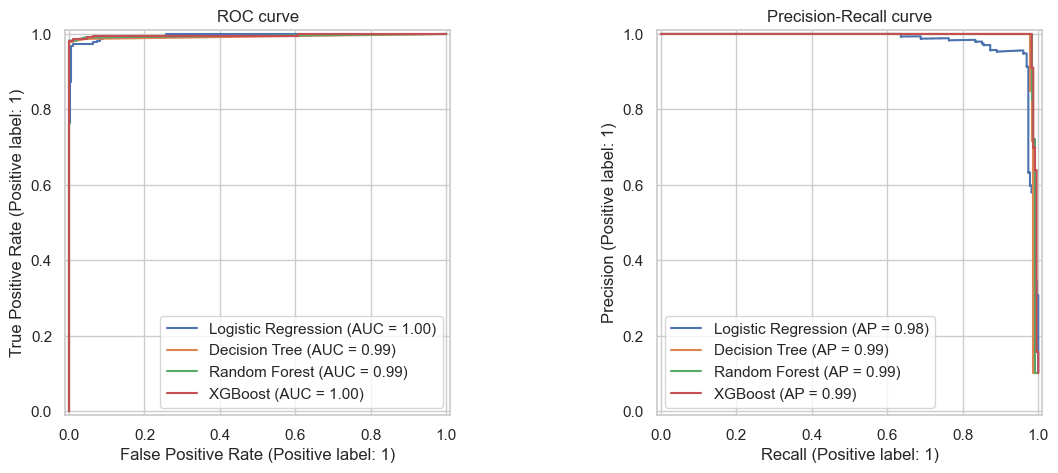

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, ax=axes[1], name=name)
axes[0].set_title('ROC curve'); axes[1].set_title('Precision-Recall curve')
plt.show()

## 10. Hyperparameter Tuning (XGBoost) + Threshold Tuning

Tuned with 5-fold stratified CV on the **training set only**. The decision threshold is then chosen from out-of-fold
predictions on the training set, so the test set stays untouched for the final evaluation.

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0],
    'min_child_weight': [1, 3, 5],
}

search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss',
                  random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_dist, n_iter=25, scoring='f1', cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)

print('Best CV F1:', round(search.best_score_, 4))
print('Best params:', search.best_params_)
best_model = search.best_estimator_

Best CV F1: 0.9912
Best params: {'subsample': 0.85, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


Best threshold: 0.827


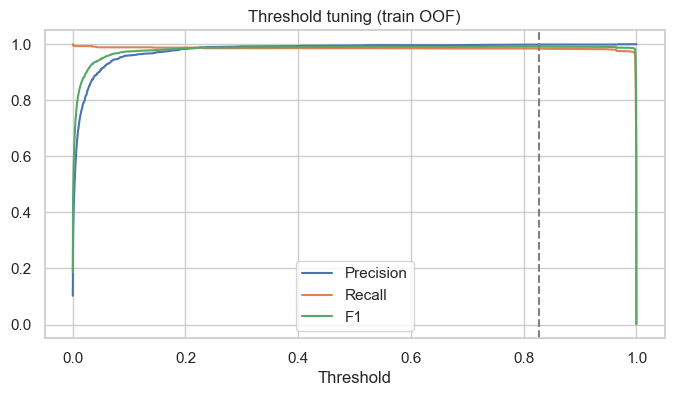

In [21]:
# choose the threshold that maximises F1 on out-of-fold training predictions
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_threshold = float(thr[np.argmax(f1s)])
print(f'Best threshold: {best_threshold:.3f}')

plt.figure(figsize=(8, 4))
plt.plot(thr, prec[:-1], label='Precision')
plt.plot(thr, rec[:-1], label='Recall')
plt.plot(thr, f1s, label='F1')
plt.axvline(best_threshold, color='grey', ls='--')
plt.xlabel('Threshold'); plt.legend(); plt.title('Threshold tuning (train OOF)')
plt.show()

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
"XGBoost (default, t=0.5)",0.9978,0.9956,0.9825,0.9890,0.9968,0.9930
"XGBoost (tuned, t=0.5)",0.9978,0.9956,0.9825,0.9890,0.9992,0.9956
"XGBoost (tuned, t=0.83)",0.9978,1.0000,0.9781,0.9889,0.9992,0.9956


              precision    recall  f1-score   support

   Not Fraud     0.9975    1.0000    0.9988      2001
       Fraud     1.0000    0.9781    0.9889       228

    accuracy                         0.9978      2229
   macro avg     0.9988    0.9890    0.9938      2229
weighted avg     0.9978    0.9978    0.9977      2229



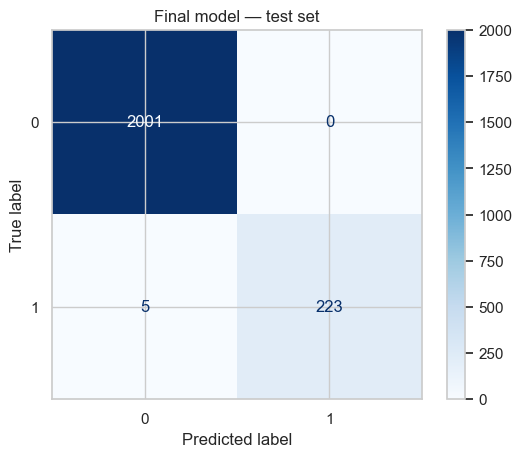

In [22]:
final = pd.DataFrame({
    'XGBoost (default, t=0.5)': evaluate(models['XGBoost'], X_test, y_test),
    'XGBoost (tuned, t=0.5)': evaluate(best_model, X_test, y_test),
    f'XGBoost (tuned, t={best_threshold:.2f})': evaluate(best_model, X_test, y_test, best_threshold),
}).T
display(final.style.format('{:.4f}'))

test_pred = (best_model.predict_proba(X_test)[:, 1] >= best_threshold).astype(int)
print(classification_report(y_test, test_pred, target_names=['Not Fraud', 'Fraud'], digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, cmap='Blues')
plt.title('Final model — test set')
plt.show()

In [23]:
train_scores = evaluate(best_model, X_train, y_train)
test_scores = evaluate(best_model, X_test, y_test)

comparison = pd.DataFrame({
    'Train (threshold=0.5)': train_scores,
    'Test (threshold=0.5)': test_scores,
})
comparison['Train-Test gap'] = (
    comparison['Train (threshold=0.5)'] - comparison['Test (threshold=0.5)']
)

display(comparison.style.format('{:.4f}'))

print(f"Best cross-validation F1: {search.best_score_:.4f}")
print(f"Train F1: {train_scores['F1']:.4f}")
print(f"Test F1:  {test_scores['F1']:.4f}")

,Train (threshold=0.5),Test (threshold=0.5),Train-Test gap
Accuracy,0.9999,0.9978,0.0021
Precision,0.9989,0.9956,0.0034
Recall,1.0000,0.9825,0.0175
F1,0.9995,0.9890,0.0105
ROC-AUC,1.0000,0.9992,0.0008
PR-AUC,1.0000,0.9956,0.0044


Best cross-validation F1: 0.9912
Train F1: 0.9995
Test F1:  0.9890


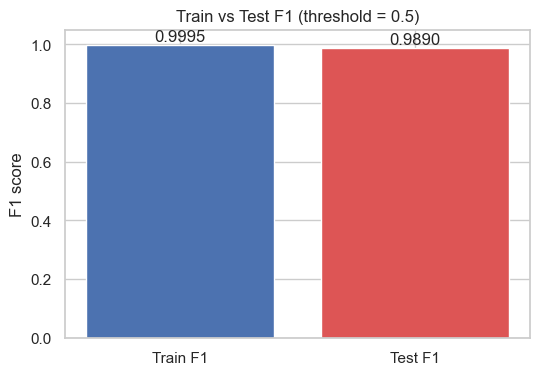

In [24]:
f1_values = [train_scores['F1'], test_scores['F1']]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Train F1', 'Test F1'], f1_values, color=['#4C72B0', '#DD5555'])

ax.set_ylim(0, 1.05)
ax.set_ylabel('F1 score')
ax.set_title('Train vs Test F1 (threshold = 0.5)')

for bar, value in zip(bars, f1_values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01,
            f'{value:.4f}', ha='center')

plt.show()

## 11. Feature Importance

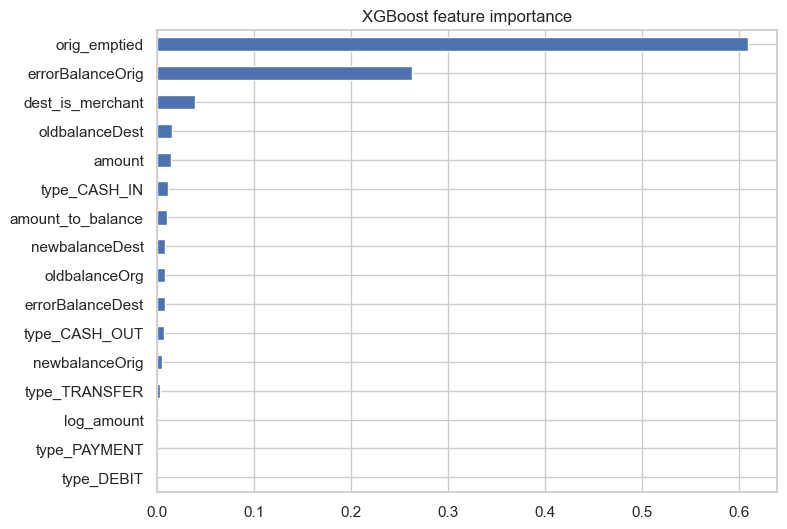

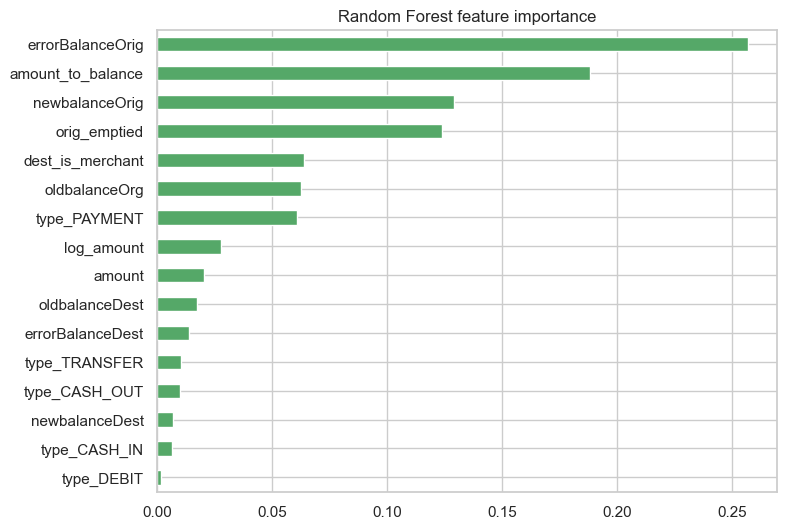

In [25]:
imp = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(8, 6))
imp.plot(kind='barh', color='#4C72B0')
plt.title('XGBoost feature importance')
plt.show()

rf_imp = pd.Series(models['Random Forest'].feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(8, 6))
rf_imp.plot(kind='barh', color='#55A868')
plt.title('Random Forest feature importance')
plt.show()

## 12. Robustness Check

The scores above are very high because this dataset is a **simulated (PaySim) sample** where fraud follows a clean pattern
(the origin account is emptied, so the balance-error features are almost perfect separators).
To show the model is not relying on one trick, we retrain **without** the balance-derived engineered features.

In [26]:
drop_cols = ['errorBalanceOrig', 'errorBalanceDest', 'orig_emptied', 'amount_to_balance']
reduced = XGBClassifier(**search.best_params_, scale_pos_weight=scale_pos_weight,
                        eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1)
reduced.fit(X_train.drop(columns=drop_cols), y_train)

pd.DataFrame({
    'All features': evaluate(best_model, X_test, y_test),
    'Without balance-error features': evaluate(reduced, X_test.drop(columns=drop_cols), y_test),
}).T.style.format('{:.4f}')

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
All features,0.9978,0.9956,0.9825,0.9890,0.9992,0.9956
Without balance-error features,0.9910,0.9333,0.9825,0.9573,0.9976,0.9916


## 13. Save Model & Prediction Function

In [24]:
artifact = {'model': best_model, 'threshold': best_threshold, 'features': FEATURES}
joblib.dump(artifact, 'fraud_model_v1.pkl')
print('Saved -> fraud_model_v1.pkl')

Saved -> fraud_model_v1.pkl


In [25]:
def predict_transaction(txn: dict, artifact_path='fraud_model_v1.pkl'):
    art = joblib.load(artifact_path)
    X_new = build_features(pd.DataFrame([txn]))[art['features']]
    proba = float(art['model'].predict_proba(X_new)[0, 1])
    return {'fraud_probability': round(proba, 4),
            'prediction': 'FRAUD' if proba >= art['threshold'] else 'NOT FRAUD'}

# example 1: account fully emptied via TRANSFER (typical fraud pattern)
print(predict_transaction({
    'type': 'TRANSFER', 'amount': 181000.0,
    'oldbalanceOrg': 181000.0, 'newbalanceOrig': 0.0,
    'nameDest': 'C553264065', 'oldbalanceDest': 0.0, 'newbalanceDest': 0.0}))

# example 2: normal merchant payment
print(predict_transaction({
    'type': 'PAYMENT', 'amount': 9839.64,
    'oldbalanceOrg': 170136.0, 'newbalanceOrig': 160296.36,
    'nameDest': 'M1979787155', 'oldbalanceDest': 0.0, 'newbalanceDest': 0.0}))

{'fraud_probability': 0.9996, 'prediction': 'FRAUD'}
{'fraud_probability': 0.0004, 'prediction': 'NOT FRAUD'}


## 14. Conclusion

- Fraud only occurs in **TRANSFER** and **CASH_OUT** transactions and typically **empties the origin account**.
- `step` was removed because it leaks the label in this sample.
- Engineered balance-error features are the strongest predictors.
- The tuned **XGBoost** model with an optimised threshold is the final Version 1 model (`fraud_model_v1.pkl`).
- Results are very high because the data is simulated; the robustness check shows performance without the strongest features.

**Next — Version 2 (AI-powered):** anomaly detection (Isolation Forest / Autoencoder), SHAP explanations,
and LLM-generated natural-language explanations for each flagged transaction.